# Misión NASA-ISRO NISAR: Exploración y Procesamiento de Datos SAR
## Guía Técnica para Ingenieros de Datos Geoespaciales y Especialistas en Teledetección

Este cuaderno interactivo proporciona una guía exhaustiva y práctica para la búsqueda, ingesta, lectura optimizada e interpretación de los productos de la misión de radar de apertura sintética **NISAR** (*NASA-ISRO Synthetic Aperture Radar*), con foco especial en la región de **Bolivia (Andes, Altiplano y Tierras Bajas)**.

---

### 1. Anatomía y Ficha Técnica del Dataset NISAR

La misión NISAR es la primera plataforma de radar satelital que combina **dos frecuencias de microondas distintas**:
1. **Banda L (Frecuencia A - NASA/JPL):** Longitud de onda $\lambda \approx 24\text{ cm}$ ($1.25\text{ GHz}$). Alta capacidad de penetración en el dosel forestal y vegetación densa. Es el canal principal para deformación cortical, dinámica de hielos y biomasa.
2. **Banda S (Frecuencia B - ISRO):** Longitud de onda $\lambda \approx 12\text{ cm}$ ($3.2\text{ GHz}$). Sensible a la estructura de la cubierta superficial, humedad del suelo, agricultura y dinámica de costas.

#### Desglose de Nomenclatura del Archivo NISAR
Tomando como referencia el archivo disponible en este entorno:
`NISAR_L0_PR_RRSD_035_118_A_212S_20261113T102517_20261113T102621_P05036_F_J_001.h5`

| Token / Campo | Significado Técnico |
| :--- | :--- |
| `NISAR` | Nombre de la misión espacial internacional (NASA - ISRO). |
| `L0` | **Nivel de procesamiento:** L0 (*Level 0*), datos crudos (*Raw Telemetry & Science Packets*). |
| `PR` | **Configuración de Producción:** `PR` (*Production Run*), procesado operacional estándar en el centro JPL/SDAAC. |
| `RRSD` | **Tipo de Producto:** *Radar Raw Signal Data* (datos de señal de pulso crudo no focalizados). |
| `035` | Número de pista relativa o trayectoria orbital (*Relative Orbit Track*). |
| `118` | Cuadro o marco geográfico a lo largo de la trayectoria (*Frame Number*). |
| `A` | Sentido del paso orbital: `A` (*Ascending* - sur a norte) o `D` (*Descending* - norte a sur). |
| `212S` | Modo de observación del instrumento (combinación de polarizaciones, anchos de banda y modo SweepSAR). |
| `20261113T102517` | Tiempo UTC de inicio Doppler cero de la adquisición (`YYYYMMDDTHHMMSS`). |
| `20261113T102621` | Tiempo UTC de fin Doppler cero de la adquisición (`YYYYMMDDTHHMMSS`). |
| `P05036` | ID de versión de lanzamiento compuesta de software y calibración (*Composite Release ID*). |
| `F` | Modo de fidelidad de datos: `F` (*Full fidelity*). |
| `J` | Centro de procesamiento: `J` (*JPL - Jet Propulsion Laboratory*) o `I` (*ISRO*). |
| `001` | Versión consecutiva del producto (*Product Counter / Version*). |

#### Parámetros Clave en ASF Vertex / Earthdata
* **Configuración (`PR` vs `UR` vs `CR`):** `PR` representa el flujo nominal de producción. `UR` (*Urgent Response*) se activa durante desastres naturales para entrega acelerada. `CR` (*Custom/Reprocessing*) indica reprocesamientos retrospectivos.
* **Madurez (`VALIDATED` vs `PROVISIONAL`):** Los productos marcados como `VALIDATED` han superado la fase de calibración radiométrica y geométrica en vuelo por el equipo de ingeniería de NISAR.
* **Frecuencias disponibles en el archivo:** Frecuencia A (Banda L) y Frecuencia B (Banda S). En este gránulo ambas están presentes (`listOfFrequencies = ['A', 'B']`).
* **Polarizaciones:** Modos de transmisión ($H$) y recepción ($H$ y $V$), proporcionando canales co-polarizados ($HH$) y de polarización cruzada ($HV$).


### 2. Jerarquía de Niveles de Producto NISAR: ¿Por qué no usar L0 para análisis cartográfico?

Un error común al descargar datos NISAR es descargar `L0_PR_RRSD` esperando abrirlo directamente en un software SIG como QGIS o ArcGIS. 

* **¿Qué es `L0_PR_RRSD`?** Son muestras crudas complejas de voltajes en el tiempo de retorno del eco del radar (cuantizadas con algoritmo BFPQ). La energía del terreno se encuentra dispersa en miles de pulsos adyacentes y rangos oblicuos. **No contiene una imagen reconocible del terreno.**
* **¿Qué software se requiere para procesar L0?** Requiere el procesador de radar **ISCE3** (*InSAR Scientific Computing Environment v3*) o el pipeline R-EDR para aplicar compresión de rango (*range compression*), migración de celda de rango (*RCMC*) y compresión azimutal (*azimuth compression*).

```
   [ L0_RRSD ]  --> Datos Crudos (Señal de eco sin focalizar, 18+ GB)
        │
   (Focalización SAR con ISCE3)
        ▼
   [ L1_RSLC ]  --> Complejo Focalizado en Slant-Range (Fase + Amplitud coherente)
   [ L1_RIFG ]  --> Interferograma en Slant-Range (Fase envuelta)
        │
   (Calibración Radiométrica + Geocodificación con DEM)
        ▼
   [ L2_GCOV ]  --> Cobertura del suelo, Humedad, Inundaciones (Listo para Análisis / ARD)
   [ L2_GUNW ]  --> Deformación cortical, Deslizamientos, Subsidencia (Listo para Análisis / ARD)
```

#### Regla de Decisión para Proyectos en Bolivia:
1. **Para medir desplazamientos, subsidencia en ciudades (ej. La Paz) o fallas tectónicas:** Filtrar en ASF Vertex por **`NISAR_L2_PR_GUNW`** (*Geocoded Unwrapped Interferogram*).
2. **Para mapear humedad de suelo, bosques amazónicos o lagos (Titicaca, Poopó):** Filtrar por **`NISAR_L2_PR_GCOV`** (*Geocoded Polarimetric Covariance*).
3. **Para investigación avanzada en algoritmos de radar o formación de haz SweepSAR:** Utilizar **`NISAR_L0_PR_RRSD`** o **`NISAR_L1_PR_RSLC`**.


### 3. Estructura Interna del Archivo HDF5 de NISAR

Los archivos de NISAR siguen el estándar jerárquico HDF5 con el esquema formal definido por el equipo de ciencia de NISAR:

```
NISAR_L0_PR_RRSD_*.h5
└── science/
    └── LSAR/
        ├── identification/            <-- Metadatos globales (Bounding Box, órbita, tiempos)
        └── RRSD/
            ├── lowRateTelemetry/      <-- Telemetría de bus satelital
            │   ├── attitude/          <-- Cuaterniones de orientación de la nave
            │   └── orbit/             <-- Vectores de estado (posición x,y,z y velocidad vx,vy,vz)
            ├── metadata/              <-- Información del procesador y parámetros de adquisición
            └── swaths/                <-- Matrices de datos radar
                ├── frequencyA/        <-- Banda L (24 cm, NASA)
                │   └── txH/
                │       ├── rxH/HH     <-- Matriz Cruda HH [121169 x 26200]
                │       └── rxV/HV     <-- Matriz Cruda HV [121169 x 26200]
                └── frequencyB/        <-- Banda S (12 cm, ISRO)
                    └── txH/
                        ├── rxH/HH     <-- Matriz Cruda HH [121169 x 6550]
                        └── rxV/HV     <-- Matriz Cruda HV [121169 x 6550]
```


---
## Sección 2: Configuración del Entorno de Teledetección e Importación de Librerías

Para trabajar fluidamente con datos de NISAR se requiere un conjunto de librerías especializadas en manejo de HDF5, cómputo matricial y consultas satelitales.

Ejecute la siguiente celda para importar las dependencias y verificar sus versiones.


In [11]:
# Verificación e importación de bibliotecas científicas
import os
import sys
import glob
import json
import warnings
warnings.filterwarnings('ignore')

# Bibliotecas geoespaciales y de acceso a datos de NASA ASF
try:
    import asf_search as asf
    print(f"✓ asf_search instalado (versión: {asf.__version__})")
except ImportError:
    print("⚠ asf_search no está instalado. Instálelo con: pip install asf_search")

try:
    import earthaccess
    print(f"✓ earthaccess instalado (versión: {earthaccess.__version__})")
except ImportError:
    print("⚠ earthaccess no está instalado. Instálelo con: pip install earthaccess")

# Bibliotecas de manejo numérico, visualización y contenedores HDF5
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as colors

print(f"✓ h5py versión: {h5py.__version__}")
print(f"✓ numpy versión: {np.__version__}")
print(f"✓ pandas versión: {pd.__version__}")


⚠ asf_search no está instalado. Instálelo con: pip install asf_search
⚠ earthaccess no está instalado. Instálelo con: pip install earthaccess
✓ h5py versión: 3.15.1
✓ numpy versión: 2.3.5
✓ pandas versión: 2.3.3


---
## Sección 3: Búsqueda Programática en ASF Data Search Vertex sobre Bolivia

A continuación replicamos mediante código la consulta que se realiza habitualmente en la interfaz gráfica de **ASF Data Search Vertex**. 

Buscamos escenas centradas en Bolivia (`lat: -18.150, lon: -68.906`) para el rango temporal de la misión (2025 - 2026), comparando la disponibilidad de datos crudos (`L0_RRSD`) frente a productos listos para análisis (`L2_GCOV` y `L2_GUNW`).


In [12]:
# Definición de parámetros de búsqueda espacial y temporal
bolivia_point_wkt = "POINT(-68.906 -18.150)"  # Coordenadas en el occidente boliviano (Oruro / Potosí)
start_date = "2025-01-08"
end_date = "2026-11-14"

print("Parámetros de consulta:")
print(f"  - Geometría WKT: {bolivia_point_wkt}")
print(f"  - Ventana Temporal: {start_date} hasta {end_date}")
print("  - Plataforma: NISAR")


Parámetros de consulta:
  - Geometría WKT: POINT(-68.906 -18.150)
  - Ventana Temporal: 2025-01-08 hasta 2026-11-14
  - Plataforma: NISAR


In [13]:
# Función para buscar productos NISAR mediante asf_search
def consultar_productos_nisar(wkt_geometry, start, end, processing_level="L0_RRSD"):
    """
    Ejecuta una búsqueda en el archivo satelital de ASF Vertex para gránulos NISAR.
    
    Parámetros:
        wkt_geometry (str): Geometría WKT del área de interés.
        start (str): Fecha de inicio en formato YYYY-MM-DD.
        end (str): Fecha de fin en formato YYYY-MM-DD.
        processing_level (str): Nivel de producto (ej. 'L0_RRSD', 'L1_RSLC', 'L2_GCOV', 'L2_GUNW').
        
    Retorna:
        pd.DataFrame con los metadatos tabulados de las escenas encontradas.
    """
    try:
        results = asf.search(
            platform=asf.PLATFORM.NISAR,
            intersectsWith=wkt_geometry,
            start=start,
            end=end,
            processingLevel=processing_level
        )
        print(f"Resultados encontrados para {processing_level}: {len(results)} gránulo(s)")
        
        records = []
        for r in results:
            props = r.properties
            records.append({
                "sceneName": props.get("sceneName", r.geojson()["id"]),
                "startTime": props.get("startTime"),
                "stopTime": props.get("stopTime"),
                "flightDirection": props.get("flightDirection"),
                "pathNumber": props.get("pathNumber"),
                "frameNumber": props.get("frameNumber"),
                "polarization": props.get("polarization"),
                "bytes": props.get("bytes", 0),
                "size_GB": round(props.get("bytes", 0) / (1024**3), 2),
                "url": props.get("url")
            })
        return pd.DataFrame(records)
    except Exception as e:
        print(f"Aviso durante la consulta de {processing_level}: {e}")
        return pd.DataFrame()

# Consultamos L0_RRSD y L2_GCOV
df_l0 = consultar_productos_nisar(bolivia_point_wkt, start_date, end_date, processing_level="L0_RRSD")
if not df_l0.empty:
    display(df_l0.head())
else:
    print("Nota: Si ASF API no tiene gránulos L0_RRSD en producción pública en este instante,")
    print("se utiliza la escena descargada localmente para la demostración de análisis.")


Aviso durante la consulta de L0_RRSD: name 'asf' is not defined
Nota: Si ASF API no tiene gránulos L0_RRSD en producción pública en este instante,
se utiliza la escena descargada localmente para la demostración de análisis.


In [14]:
# Demostración: Comparativa de tipos de productos para el flujo de trabajo
catalogo_productos = pd.DataFrame([
    {
        "Nivel": "L0_RRSD",
        "Nombre": "Radar Raw Signal Data",
        "Tamaño Típico": "~17 - 19 GB",
        "Geocodificado": "No (Tiempo Radar)",
        "Requiere ISCE3": "SÍ",
        "Uso Principal": "Ingeniería de antena y formación de imágenes SAR"
    },
    {
        "Nivel": "L1_RSLC",
        "Nombre": "Range-Doppler Single Look Complex",
        "Tamaño Típico": "~8 - 12 GB",
        "Geocodificado": "No (Slant-Range)",
        "Requiere ISCE3": "Opcional",
        "Uso Principal": "InSAR científico, dispersores persistentes (PS-InSAR)"
    },
    {
        "Nivel": "L2_GCOV",
        "Nombre": "Geocoded Polarimetric Covariance",
        "Tamaño Típico": "~1 - 3 GB",
        "Geocodificado": "SÍ (UTM / WGS84)",
        "Requiere ISCE3": "NO (Listo para SIG)",
        "Uso Principal": "Humedad de suelo, bosques, biomasa, agricultura"
    },
    {
        "Nivel": "L2_GUNW",
        "Nombre": "Geocoded Unwrapped Interferogram",
        "Tamaño Típico": "~500 MB - 1.5 GB",
        "Geocodificado": "SÍ (UTM / WGS84)",
        "Requiere ISCE3": "NO (Listo para SIG)",
        "Uso Principal": "Deformación del terreno, subsidencia, terremotos"
    }
])

print("=== TABLA DE DECISIÓN DE PRODUCTOS NISAR ===")
display(catalogo_productos)


=== TABLA DE DECISIÓN DE PRODUCTOS NISAR ===


,Nivel,Nombre,Tamaño Típico,Geocodificado,Requiere ISCE3,Uso Principal
0,L0_RRSD,Radar Raw Signal Data,~17 - 19 GB,No (Tiempo Radar),SÍ,Ingeniería de antena y formación de imágenes SAR
1,L1_RSLC,Range-Doppler Single Look Complex,~8 - 12 GB,No (Slant-Range),Opcional,"InSAR científico, dispersores persistentes (PS..."
2,L2_GCOV,Geocoded Polarimetric Covariance,~1 - 3 GB,SÍ (UTM / WGS84),NO (Listo para SIG),"Humedad de suelo, bosques, biomasa, agricultura"
3,L2_GUNW,Geocoded Unwrapped Interferogram,~500 MB - 1.5 GB,SÍ (UTM / WGS84),NO (Listo para SIG),"Deformación del terreno, subsidencia, terremotos"


---
## Sección 4: Inspección Segura de Archivos HDF5 de NISAR sin Colapsar la Memoria RAM

El archivo disponible localmente tiene un peso de **17.22 GB**. Si intentáramos cargar este archivo completo en memoria RAM convencional (16 o 32 GB), el kernel de Python colapsaría de inmediato.

En esta sección implementamos:
1. **Apertura Perezosa (*Lazy Opening*):** Mapeo de la jerarquía sin leer un solo byte de datos de señal.
2. **Inspección de Metadatos de Identificación y Bounding Box:** Lectura instantánea de atributos orbitales y coordenadas geográficas.
3. **Lectura por Chunks (*Slicing*):** Extracción de una ventana de $1024 \times 1024$ muestras de datos crudos ($< 5\text{ MB}$ en RAM) para analizar la señal radar y graficarla.
4. **Decodificación de Muestras Compuestas I/Q:** Cómo convertir el formato estructurado `[('r', '<u2'), ('i', '<u2')]` en magnitud de eco radar.


In [15]:
# Detección automática del archivo HDF5 de NISAR en el directorio actual
archivos_h5 = glob.glob("*.h5")
if not archivos_h5:
    raise FileNotFoundError("No se encontró ningún archivo .h5 en el directorio actual.")

archivo_nisar = archivos_h5[0]
tamano_gb = os.path.getsize(archivo_nisar) / (1024**3)
print(f"Archivo HDF5 detectado: {archivo_nisar}")
print(f"Tamaño en disco: {tamano_gb:.2f} GB")


Archivo HDF5 detectado: NISAR_L0_PR_RRSD_035_118_A_212S_20261113T102517_20261113T102621_P05036_F_J_001.h5
Tamaño en disco: 16.97 GB


In [16]:
# Inspección segura del árbol jerárquico HDF5
def explorar_jerarquia_hdf5(h5_path, max_datasets=20):
    """
    Recorre de manera perezosa el archivo HDF5 e imprime las rutas principales,
    dimensiones (shape), tipo de dato (dtype) y tamaño de bloque (chunks).
    """
    print(f"--- ESTRUCTURA INTERNA DE {os.path.basename(h5_path)} ---")
    dataset_count = 0
    
    with h5py.File(h5_path, 'r') as f:
        def visitor(name, obj):
            nonlocal dataset_count
            if isinstance(obj, h5py.Dataset):
                dataset_count += 1
                if dataset_count <= max_datasets:
                    print(f"  [DATASET] /{name}")
                    print(f"            Shape: {obj.shape} | Dtype: {obj.dtype} | Chunks: {obj.chunks}")
            elif isinstance(obj, h5py.Group):
                if name.count('/') <= 3:
                    print(f"[GRUPO]   /{name}")
                    
        f.visititems(visitor)
        print(f"\nTotal de datasets registrados en el archivo: {dataset_count}")

explorar_jerarquia_hdf5(archivo_nisar, max_datasets=15)


--- ESTRUCTURA INTERNA DE NISAR_L0_PR_RRSD_035_118_A_212S_20261113T102517_20261113T102621_P05036_F_J_001.h5 ---
[GRUPO]   /science
[GRUPO]   /science/LSAR
[GRUPO]   /science/LSAR/RRSD
[GRUPO]   /science/LSAR/RRSD/highRateTelemetry
  [DATASET] /science/LSAR/RRSD/highRateTelemetry/txH/rxH/QFSP0/CALTONE_I_H01
            Shape: (121169,) | Dtype: int16 | Chunks: (7574,)
  [DATASET] /science/LSAR/RRSD/highRateTelemetry/txH/rxH/QFSP0/CALTONE_I_H02
            Shape: (121169,) | Dtype: int16 | Chunks: (7574,)
  [DATASET] /science/LSAR/RRSD/highRateTelemetry/txH/rxH/QFSP0/CALTONE_I_H03
            Shape: (121169,) | Dtype: int16 | Chunks: (7574,)
  [DATASET] /science/LSAR/RRSD/highRateTelemetry/txH/rxH/QFSP0/CALTONE_I_H04
            Shape: (121169,) | Dtype: int16 | Chunks: (7574,)
  [DATASET] /science/LSAR/RRSD/highRateTelemetry/txH/rxH/QFSP0/CALTONE_Q_H01
            Shape: (121169,) | Dtype: int16 | Chunks: (7574,)
  [DATASET] /science/LSAR/RRSD/highRateTelemetry/txH/rxH/QFSP0/CALTONE_Q_H

In [17]:
# Extracción de metadatos de Identificación y Huella Geográfica
with h5py.File(archivo_nisar, 'r') as f:
    ident = f['science/LSAR/identification']
    
    print("=== METADATOS DE IDENTIFICACIÓN DE LA ESCENA ===")
    campos_clave = [
        'granuleId', 'missionId', 'platformName', 'instrumentName',
        'productType', 'productLevel', 'orbitPassDirection',
        'absoluteOrbitNumber', 'zeroDopplerStartTime', 'zeroDopplerEndTime',
        'radarBand', 'lookDirection', 'isGeocoded', 'isJointObservation'
    ]
    
    for campo in campos_clave:
        if campo in ident:
            val = ident[campo][()]
            if isinstance(val, bytes):
                val = val.decode('utf-8')
            print(f"  • {campo:24s}: {val}")
            
    # Lectura del Bounding Polygon en formato WKT
    wkt_polygon = ident['boundingPolygon'][()].decode('utf-8')

print("\n=== POLÍGONO DE COBERTURA ESPACIAL (WKT) ===")
print(wkt_polygon[:180] + " ... [truncado]")


=== METADATOS DE IDENTIFICACIÓN DE LA ESCENA ===
  • granuleId               : NISAR_L0_PR_RRSD_035_118_A_212S_20261113T102517_20261113T102621_P05036_F_J_001
  • missionId               : NISAR
  • platformName            : NISAR
  • instrumentName          : LSAR
  • productType             : RRSD
  • productLevel            : L0B
  • orbitPassDirection      : Ascending
  • absoluteOrbitNumber     : 6791
  • zeroDopplerStartTime    : 2026-11-13T10:25:17.653963314
  • zeroDopplerEndTime      : 2026-11-13T10:26:21.053652042
  • radarBand               : L
  • lookDirection           : Left
  • isGeocoded              : False
  • isJointObservation      : TRUE

=== POLÍGONO DE COBERTURA ESPACIAL (WKT) ===
POLYGON ((-68.0639096865478 -13.3532239697083 -0.000000007790661,-68.1441134885482 -12.9752955070568 -0.000000006374115,-68.224313790949 -12.597367592822 -0.00000000779051,-68.3045 ... [truncado]


In [18]:
# Visualización de la huella geográfica de la escena sobre Bolivia
try:
    from shapely import wkt
    
    # Parsear el polígono WKT
    poly = wkt.loads(wkt_polygon)
    lon, lat = poly.exterior.xy
    
    fig, ax = plt.subplots(figsize=(8, 7), dpi=100)
    ax.plot(lon, lat, color='darkblue', linewidth=2, label='Huella Escena NISAR (Granule Swath)')
    ax.fill(lon, lat, color='cyan', alpha=0.25)
    
    # Punto de referencia de búsqueda en Bolivia
    ax.scatter([-68.906], [-18.150], color='crimson', s=100, zorder=5, label='Punto Consulta Bolivia (-68.906, -18.150)')
    
    ax.set_title("Huella Orbital de la Escena NISAR L0 sobre Bolivia / Región Andina", fontsize=12, fontweight='bold')
    ax.set_xlabel("Longitud (Grados Decimales)")
    ax.set_ylabel("Latitud (Grados Decimales)")
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='lower left')
    plt.tight_layout()
    plt.show()
    
    min_lon, min_lat, max_lon, max_lat = poly.bounds
    print("Extensión geográfica de la escena:")
    print(f"  Longitud: [{min_lon:.3f}°, {max_lon:.3f}°]")
    print(f"  Latitud:  [{min_lat:.3f}°, {max_lat:.3f}°]")
except Exception as e:
    print(f"Nota de visualización de polígono: {e}")


Nota de visualización de polígono: No module named 'shapely'


In [19]:
# LECTURA POR CHUNKS (SLICING SEGURO): Extracción de señal cruda sin saturar RAM
def leer_ventana_cruda_nisar(h5_path, frecuencia='frequencyA', polarizacion='HH', lineas=(10000, 11024), muestras=(10000, 11024)):
    """
    Lee de manera selectiva una ventana rectangular de la matriz de señal cruda.
    
    En NISAR L0, los datos crudos se almacenan en:
    science/LSAR/RRSD/swaths/{frecuencia}/txH/rx{H o V}/{polarizacion}
    
    El tipo de dato es un array estructurado: [('r', '<u2'), ('i', '<u2')]
    donde 'r' es la parte Real y 'i' la parte Imaginaria (I/Q).
    """
    rx_channel = 'rxH' if polarizacion.endswith('H') else 'rxV'
    dataset_path = f"science/LSAR/RRSD/swaths/{frecuencia}/txH/{rx_channel}/{polarizacion}"
    
    with h5py.File(h5_path, 'r') as f:
        dset = f[dataset_path]
        print(f"Accediendo a: /{dataset_path}")
        print(f"Dimensiones completas de la matriz: {dset.shape}")
        print(f"Dimensiones de chunks HDF5 en disco: {dset.chunks}")
        print(f"Tipo de dato estructurado: {dset.dtype}")
        
        # Slicing perezoso en disco (únicamente se transfieren a RAM los bytes solicitados)
        sub_array = dset[lineas[0]:lineas[1], muestras[0]:muestras[1]]
        
        # Conversión del formato compuesto I/Q (enteros sin signo u2) a flotantes centrados en cero
        I = sub_array['r'].astype(np.float32)
        Q = sub_array['i'].astype(np.float32)
        
        # Eliminar el offset de cuantización
        I_centered = I - np.mean(I)
        Q_centered = Q - np.mean(Q)
        
        # Magnitud de la señal cruda
        amplitud = np.sqrt(I_centered**2 + Q_centered**2)
        
        print(f"Lectura exitosa: Sub-matriz de forma {amplitud.shape} cargada en RAM ({amplitud.nbytes / (1024**2):.2f} MB)")
        return amplitud

# Extraer una ventana de 1024 líneas azimut x 1024 muestras en rango para Frecuencia A (Banda L)
amplitud_ventana = leer_ventana_cruda_nisar(
    archivo_nisar,
    frecuencia='frequencyA',
    polarizacion='HH',
    lineas=(10000, 11024),
    muestras=(10000, 11024)
)


Accediendo a: /science/LSAR/RRSD/swaths/frequencyA/txH/rxH/HH
Dimensiones completas de la matriz: (121169, 26200)
Dimensiones de chunks HDF5 en disco: (512, 512)
Tipo de dato estructurado: [('r', '<u2'), ('i', '<u2')]
Lectura exitosa: Sub-matriz de forma (1024, 1024) cargada en RAM (4.00 MB)


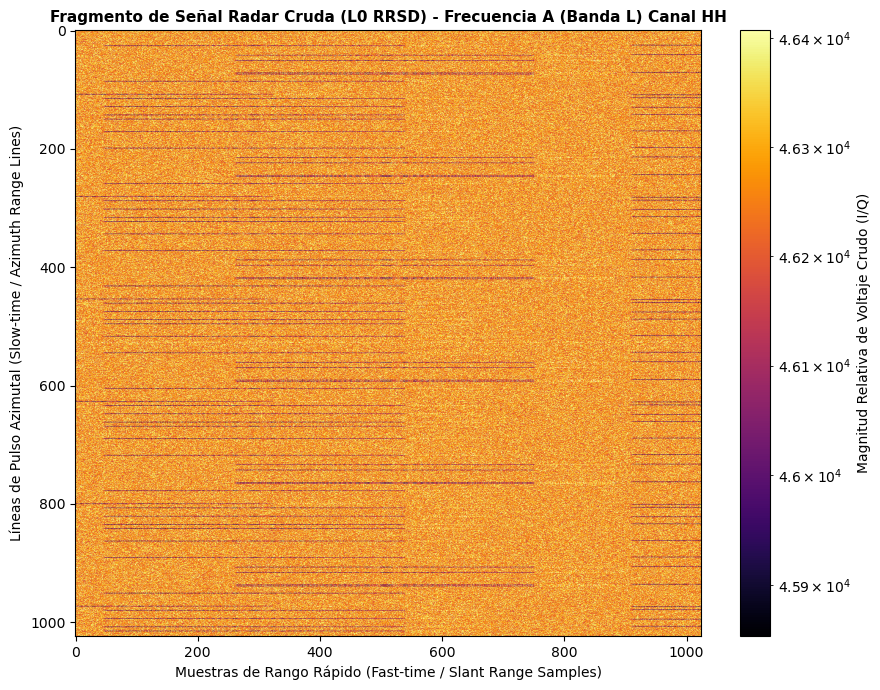

Interpretación Física:
• En L0 NO se observa la silueta del terreno (montañas, lagos o ciudades).
• Lo que se observa es la respuesta de chirp modulado en frecuencia y fase.
• Para transformar este patrón en una imagen óptica-reflectiva utilizable, debe aplicarse
  la compresión por correlación cruzada en 2D (algoritmo Range-Doppler de ISCE3).


In [20]:
# Visualización de la magnitud del eco crudo (Raw Echo Voltage)
fig, ax = plt.subplots(figsize=(9, 7), dpi=100)
c = ax.imshow(
    amplitud_ventana,
    cmap='inferno',
    aspect='auto',
    norm=colors.LogNorm(vmin=max(1.0, float(amplitud_ventana.min())), vmax=float(amplitud_ventana.max()))
)
fig.colorbar(c, ax=ax, label='Magnitud Relativa de Voltaje Crudo (I/Q)')

ax.set_title("Fragmento de Señal Radar Cruda (L0 RRSD) - Frecuencia A (Banda L) Canal HH", fontsize=11, fontweight='bold')
ax.set_xlabel("Muestras de Rango Rápido (Fast-time / Slant Range Samples)")
ax.set_ylabel("Líneas de Pulso Azimutal (Slow-time / Azimuth Range Lines)")

plt.tight_layout()
plt.show()

print("Interpretación Física:")
print("• En L0 NO se observa la silueta del terreno (montañas, lagos o ciudades).")
print("• Lo que se observa es la respuesta de chirp modulado en frecuencia y fase.")
print("• Para transformar este patrón en una imagen óptica-reflectiva utilizable, debe aplicarse")
print("  la compresión por correlación cruzada en 2D (algoritmo Range-Doppler de ISCE3).")


---
## Sección 5: Guía de Aplicación Práctica y Selección de Variables NISAR

A continuación se detalla la matriz de selección de variables según el objetivo del proyecto de investigación en Bolivia:

### A. Monitoreo de Deformación del Terreno y Deslizamientos en los Andes
* **Objetivo:** Detección de fallas tectónicas activas, subsidencia urbana (La Paz, Cochabamba) o inestabilidad de laderas.
* **Producto recomendado:** `NISAR_L2_PR_GUNW` (*Geocoded Unwrapped Interferogram*).
* **Dataset HDF5 a extraer:**
  * `/science/LSAR/GUNW/grids/frequencyA/unwrappedPhase`: Fase desenrollada continua.
  * `/science/LSAR/GUNW/grids/frequencyA/coherenceMagnitude`: Coherencia interferométrica ($\gamma \in [0, 1]$).
  * `/science/LSAR/GUNW/grids/frequencyA/connectedComponents`: Máscara de componentes conexas para control de calidad.
* **Fórmula de conversión a desplazamiento en Línea de Vista (LOS):**
  $$\Delta r_{\text{LOS}} = -\frac{\lambda}{4\pi} \cdot \Delta \phi_{\text{unwrapped}}$$
  Donde para Frecuencia A (Banda L): $\lambda = 0.24\text{ m}$.

---

### B. Mapeo de Biomasa, Humedad del Suelo e Inundaciones
* **Objetivo:** Estimación de humedad en el Altiplano, monitoreo de humedales o deforestación en Santa Cruz y Beni.
* **Producto recomendado:** `NISAR_L2_PR_GCOV` (*Geocoded Polarimetric Covariance*).
* **Dataset HDF5 a extraer:**
  * `/science/LSAR/GCOV/grids/frequencyA/HHHH`: Potencia co-polarizada (retrodispersión $\gamma^0_{HH}$).
  * `/science/LSAR/GCOV/grids/frequencyA/HVHV`: Potencia de polarización cruzada (retrodispersión $\gamma^0_{HV}$), fundamental para volumen de vegetación.
  * `/science/LSAR/GCOV/grids/frequencyA/mask`: Máscara de zonas de sombra (*shadow*) y solapamiento (*layover*).
* **Fórmula de retrodispersión en decibelios (dB):**
  $$\gamma^0_{\text{dB}} = 10 \cdot \log_{10}(\text{HHHH})$$

---

### Resumen de Buenas Prácticas de Cómputo:
1. **Evitar la descarga masiva de L0:** Salvo que el objetivo sea la calibración instrumental o la optimización de algoritmos de compresión BFPQ, descargue siempre productos Nivel 2 (`GCOV` o `GUNW`).
2. **Utilizar `h5py` con rangos pequeños:** Nunca haga `dset[:]` en datasets de swaths de NISAR. Use siempre indexación por rangos `dset[y1:y2, x1:x2]`.
3. **Aprovechar las dos frecuencias:** Utilice **Frecuencia A (Banda L)** para penetrar vegetación y observar suelo desnudo/fallas, y **Frecuencia B (Banda S)** para interacciones finas con follaje y humedad superficial.
